# Hospital Readmission Analysis: Who Comes Back Within 30 Days?

**Business question:** Which patient groups are most likely to be readmitted within 30 days of discharge, and where should a hospital focus its interventions?

**Data:** UCI Diabetes 130-US Hospitals, 1999–2008 — 101,766 encounters from 130 US hospitals. Analysis cohort: 69,985 patients (one encounter per patient).

**Tools:** Python (pandas, DuckDB, statsmodels, SciPy), SQL (DuckDB), matplotlib.

**Headline result:** 8.98% of patients were readmitted within 30 days. The strongest single signal is prior inpatient use: patients with 3+ inpatient visits in the previous year were readmitted at 26.5%, more than triple the 8.1% rate for patients with none.

> All findings below are **associations in this dataset**, not causal claims and not medical advice. The data covers diabetic patients from 1999–2008, so results describe that population and period.

## 1. Setup and load

The raw CSV is loaded into DuckDB (`data/hospital_readmission.duckdb`, table `encounters_raw`). DuckDB is used instead of pandas alone so the analysis is expressed in SQL — see the `sql/` folder for the full query set.

In [ ]:
import duckdb
import numpy as np
import pandas as pd

con = duckdb.connect('data/hospital_readmission.duckdb', read_only=True)
raw = con.execute("SELECT * FROM encounters_raw").fetchdf()
print(f"Raw encounters loaded: {len(raw):,}")
print(f"Columns: {len(raw.columns)}")
print(f"Distinct patients: {raw['patient_nbr'].nunique():,}")
print(raw['readmitted'].value_counts().to_string())


Raw encounters loaded: 101,766
Columns: 50
Distinct patients: 71,518
readmitted
NO     54864
>30    35545
<30    11357


## 2. Cleaning decisions

Every decision below is recorded here and implemented in `scripts/load_clean.py`. The full rationale is in that script's docstring.

| Decision | Reason |
|---|---|
| `?` placeholders treated as NULL | The dataset encodes missing values as `?` |
| Drop `weight` | 96.9% missing, unusable |
| Drop `payer_code` | 39.6% missing, not part of the business question |
| Drop `medical_specialty` | 49.1% missing, not part of the business question |
| Drop 3 rows with gender `Unknown/Invalid` | No usable value |
| Exclude expired (1,652) and hospice (771) discharges, plus 3 "still patient" | Those patients cannot be readmitted, so keeping them would bias the rate down |
| Keep only the FIRST encounter per patient | 16,773 patients have repeat encounters (max 40). One row per patient avoids double-counting the same person and keeps the chi-square tests' independence assumption valid |
| Group ICD-9 codes into 9 categories (Strack et al. 2014) | 700+ distinct codes are unreadable as-is; e.g. 390–459 + 785 = Circulatory, 250 = Diabetes |
| Target: `readmitted_30d` = 1 if `readmitted` is `<30`, else 0 | `NO` and `>30` both mean "not readmitted within 30 days" |

In [ ]:
# Verify the missing-value picture that drove the cleaning decisions
miss = (raw == '?').mean().sort_values(ascending=False)
print("Share of '?' (missing) by column, columns with any missing:")
print(miss[miss > 0].round(4).to_string())
print()
print("Cohort flow:")
print(f"  raw encounters:                          {len(raw):,}")
excl = raw[(raw['gender'] != 'Unknown/Invalid')
           & (~raw['discharge_disposition_id'].astype(int).isin([11, 13, 14, 19, 20, 21, 12]))]
print(f"  after outcome exclusions:                {len(excl):,}")
df = con.execute("SELECT * FROM encounters").fetchdf()
print(f"  analysis cohort (first encounter/patient): {len(df):,}")
print(f"  readmitted within 30 days:               {int(df['readmitted_30d'].sum()):,} "
      f"({100 * df['readmitted_30d'].mean():.2f}%)")


Share of '?' (missing) by column, columns with any missing:
weight               0.9686
medical_specialty    0.4908
payer_code           0.3956
race                 0.0223
diag_3               0.0140
diag_2               0.0035
diag_1               0.0002

Cohort flow:
  raw encounters:                          101,766
  after outcome exclusions:                99,337
  analysis cohort (first encounter/patient): 69,985
  readmitted within 30 days:               6,284 (8.98%)


## 3. Readmission by age, race, and gender

Readmission rises steadily with age and is essentially flat across race and gender — age is the demographic story here, not sex or race.

In [ ]:
for col in ['age_group', 'race', 'gender']:
    t = (df.groupby(col)['readmitted_30d']
           .agg(['count', 'sum', 'mean']).rename(
               columns={'count': 'n', 'sum': 'readmitted', 'mean': 'rate'}))
    t['rate_pct'] = (t['rate'] * 100).round(2)
    print(f"--- {col} ---")
    print(t[['n', 'readmitted', 'rate_pct']].to_string())
    print()


--- age_group ---
               n  readmitted  rate_pct
age_group                             
[0-10)       153           3      1.96
[10-20)      534          26      4.87
[20-30)     1121          83      7.40
[30-40)     2692         188      6.98
[40-50)     6828         506      7.41
[50-60)    12351         880      7.12
[60-70)    15688        1415      9.02
[70-80)    17748        1816     10.23
[80-90)    11110        1199     10.79
[90-100)    1760         168      9.55

--- race ---
                     n  readmitted  rate_pct
race                                        
AfricanAmerican  12627        1095      8.67
Asian              488          41      8.40
Caucasian        52303        4806      9.19
Hispanic          1501         122      8.13
Other             1149          79      6.88

--- gender ---
            n  readmitted  rate_pct
gender                             
Female  37239        3365      9.04
Male    32746        2919      8.91



## 4. Utilization: length of stay, medications, and prior visits

The gradient is steepest for prior inpatient visits: 8.1% with none, 12.9% with one, 18.5% with two, and 26.5% with three or more. Length of stay and medication count show the same direction but smaller steps.

--- los_group ---
               n  readmitted  rate_pct
los_group                             
1-2 days   22650        1621      7.16
3-4 days   21916        1861      8.49
5-7 days   15651        1650     10.54
8+ days     9768        1152     11.79

--- meds_group ---
                n  readmitted  rate_pct
meds_group                             
1-10        19497        1423      7.30
11-20       35045        3245      9.26
21+         15443        1616     10.46

--- prior_inpatient_group ---
                           n  readmitted  rate_pct
prior_inpatient_group                             
0                      61790        5022      8.13
1                       5798         747     12.88
2                       1501         278     18.52
3+                       896         237     26.45



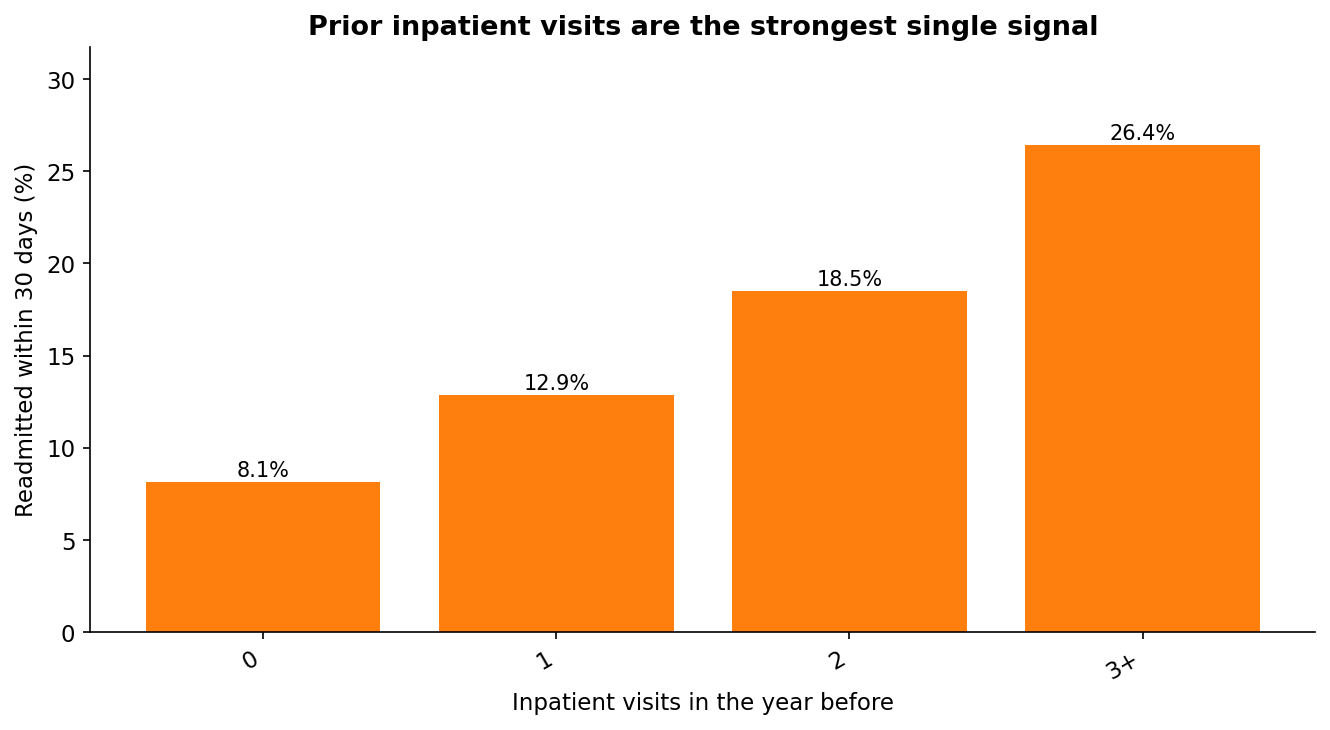

In [ ]:
for col, order in [('los_group', ['1-2 days', '3-4 days', '5-7 days', '8+ days']),
                   ('meds_group', ['1-10', '11-20', '21+']),
                   ('prior_inpatient_group', ['0', '1', '2', '3+'])]:
    t = (df.groupby(col)['readmitted_30d']
           .agg(['count', 'sum', 'mean']).rename(
               columns={'count': 'n', 'sum': 'readmitted', 'mean': 'rate'}))
    t['rate_pct'] = (t['rate'] * 100).round(2)
    t['_ord'] = pd.Categorical(t.index, categories=order, ordered=True)
    t = t.sort_values('_ord')
    print(f"--- {col} ---")
    print(t[['n', 'readmitted', 'rate_pct']].to_string())
    print()


## 5. Clinical factors: HbA1c testing, medication changes, diagnosis

Two results here need care. Patients who had an HbA1c test readmitted slightly less often (8.4% vs 9.1%), but the difference is small and disappears after adjustment in the regression below — this is an association, not evidence that testing prevents readmission. Patients whose medication was changed during the stay readmitted more often (9.4% vs 8.6%), which most likely reflects that sicker patients get their medication changed, not that the change caused the readmission.

In [ ]:
df['a1c_tested'] = np.where(df['A1Cresult'] == 'None', 'Not tested', 'Tested')
df['med_change'] = np.where(df['change'] == 'Ch', 'Changed', 'No change')
df['diab_med'] = np.where(df['diabetesMed'] == 'Yes', 'Yes', 'No')
for col in ['A1Cresult', 'a1c_tested', 'med_change', 'diabetesMed', 'diag_1_category']:
    t = (df.groupby(col)['readmitted_30d']
           .agg(['count', 'sum', 'mean']).rename(
               columns={'count': 'n', 'sum': 'readmitted', 'mean': 'rate'}))
    t['rate_pct'] = (t['rate'] * 100).round(2)
    print(f"--- {col} ---")
    print(t[['n', 'readmitted', 'rate_pct']].sort_values('rate_pct', ascending=False).to_string())
    print()


--- A1Cresult ---
               n  readmitted  rate_pct
A1Cresult                             
None       57139        5205      9.11
Norm        3741         323      8.63
>7          2866         247      8.62
>8          6239         509      8.16

--- a1c_tested ---
                n  readmitted  rate_pct
a1c_tested                             
Not tested  57139        5205      9.11
Tested      12846        1079      8.40

--- med_change ---
                n  readmitted  rate_pct
med_change                             
Changed     31495        2973      9.44
No change   38490        3311      8.60

--- diabetesMed ---
                 n  readmitted  rate_pct
diabetesMed                             
Yes          53302        5023      9.42
No           16683        1261      7.56

--- diag_1_category ---
                     n  readmitted  rate_pct
diag_1_category                             
Missing             10           2     20.00
Injury            4694         507     10.8

## 6. Discharge destination

Discharge to home is the lowest-risk destination (6.9%). Discharge to another hospital (16.3%) and to a skilled nursing / rehab facility (14.8%) are associated with far higher readmission — but that largely reflects that sicker patients are discharged to facilities, so this is a marker of severity as much as a destination effect. Even so, it tells a hospital exactly where its readmitted patients are coming from.

                                         n  readmitted  rate_pct
discharge_group                                                 
Other hospital / inpatient facility   2463         402     16.32
SNF / rehab / nursing facility       11070        1635     14.77
Other/Unknown                         3359         331      9.85
Home with home health                 8364         798      9.54
Left AMA                               409          39      9.54
Home                                 44320        3079      6.95

Discharge destination x prior inpatient visits:
                    discharge_group prior_inpatient_group  count     mean  rate_pct
                               Home                     0  39524 0.062139      6.21
                               Home                     1   3422 0.108708     10.87
                               Home                     2    863 0.152955     15.30
                               Home                    3+    511 0.232877     23.29
           

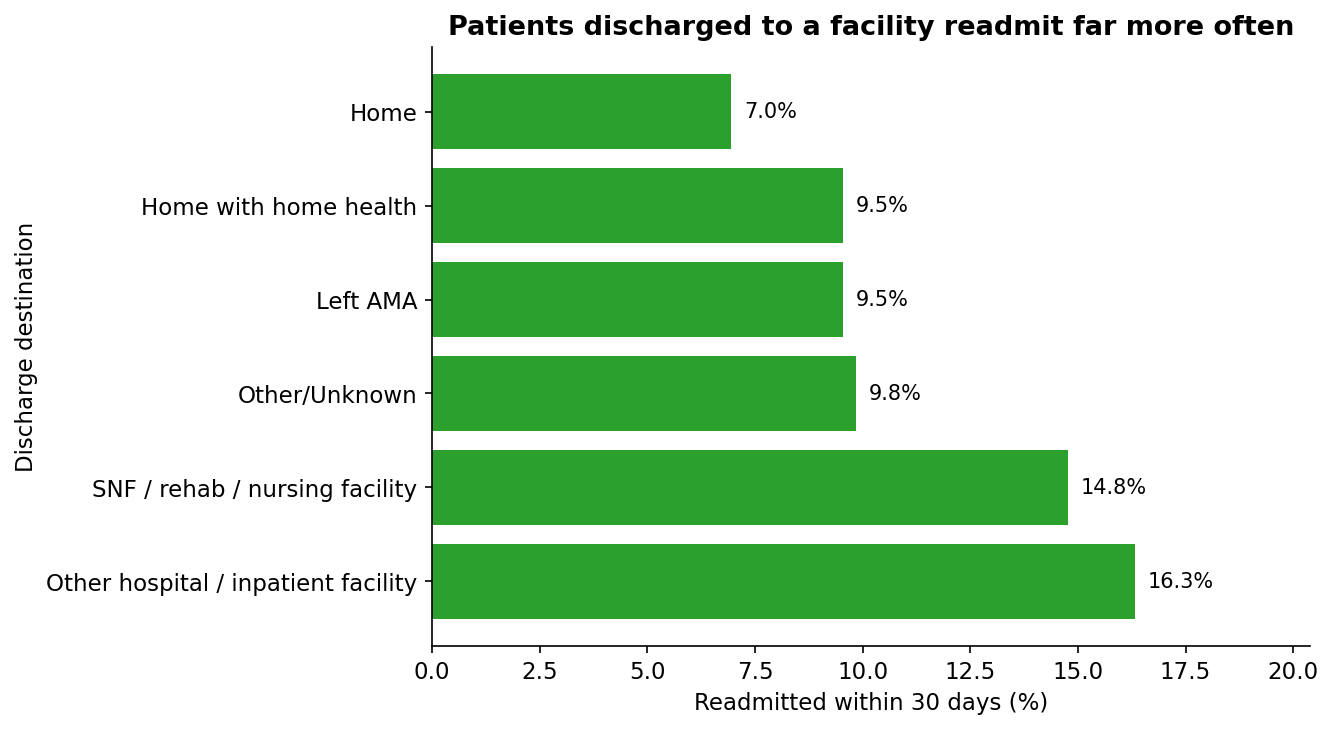

In [ ]:
t = (df.groupby('discharge_group')['readmitted_30d']
         .agg(['count', 'sum', 'mean']).rename(
             columns={'count': 'n', 'sum': 'readmitted', 'mean': 'rate'}))
t['rate_pct'] = (t['rate'] * 100).round(2)
print(t[['n', 'readmitted', 'rate_pct']].sort_values('rate_pct', ascending=False).to_string())
print()
print("Discharge destination x prior inpatient visits:")
cross = (df.groupby(['discharge_group', 'prior_inpatient_group'])['readmitted_30d']
           .agg(['count', 'mean']).reset_index())
cross['rate_pct'] = (cross['mean'] * 100).round(2)
print(cross.to_string(index=False))


## 7. Statistical testing

Chi-square tests for categorical factors, Mann-Whitney U tests for numeric ones. With ~70,000 patients, tiny differences can be "significant", so read the effect sizes next to the p-values: gender (p = 0.58) and number of procedures (p = 0.36) show no association at all, while prior inpatient visits, discharge destination, and length of stay are both significant and large.

In [ ]:
from scipy import stats

for col in ['age_group', 'race', 'gender', 'admission_type', 'discharge_group',
            'diag_1_category', 'prior_inpatient_group', 'los_group', 'meds_group',
            'a1c_tested', 'med_change']:
    ct = pd.crosstab(df[col], df['readmitted_30d'])
    chi2, p, dof, _ = stats.chi2_contingency(ct)
    print(f"{col:25s} chi2={chi2:8.2f}  dof={dof}  p={p:.2e}")
print()
for col in ['time_in_hospital', 'num_medications', 'num_lab_procedures',
            'number_inpatient', 'number_emergency', 'number_diagnoses',
            'num_procedures', 'number_outpatient']:
    a = df.loc[df['readmitted_30d'] == 1, col]
    b = df.loc[df['readmitted_30d'] == 0, col]
    u, p = stats.mannwhitneyu(a, b, alternative='two-sided')
    print(f"{col:20s} median readm {a.median():.0f} vs not {b.median():.0f} | "
          f"mean {a.mean():.2f} vs {b.mean():.2f} | p={p:.2e}")


age_group                 chi2=  188.78  dof=9  p=7.39e-36
race                      chi2=   11.79  dof=4  p=1.90e-02
gender                    chi2=    0.30  dof=1  p=5.82e-01
admission_type            chi2=   10.92  dof=3  p=1.21e-02
discharge_group           chi2=  847.06  dof=5  p=7.63e-181
diag_1_category           chi2=   75.27  dof=9  p=1.40e-12
prior_inpatient_group     chi2=  664.87  dof=3  p=8.70e-144
los_group                 chi2=  239.89  dof=3  p=1.00e-51
meds_group                chi2=  112.43  dof=2  p=3.86e-25
a1c_tested                chi2=    6.38  dof=1  p=1.15e-02
med_change                chi2=   14.76  dof=1  p=1.22e-04

time_in_hospital     median readm 4 vs not 3 | mean 4.79 vs 4.22 | p=4.78e-56
num_medications      median readm 15 vs not 14 | mean 16.62 vs 15.57 | p=2.94e-29
num_lab_procedures   median readm 46 vs not 44 | mean 44.91 vs 42.68 | p=9.72e-18
number_inpatient     median readm 0 vs not 0 | mean 0.37 vs 0.16 | p=6.72e-111
number_emergency     median

## 8. Logistic regression: adjusted odds ratios

One model, all factors together, so each odds ratio is adjusted for the others. Reference groups are the largest or lowest-risk group (age 50–60, Caucasian, male, elective admission, discharged home, diagnosis "Other", no prior inpatient visits, 1–2 day stay, 1–10 medications, HbA1c not tested, no medication change, no diabetes medication).

The model fits modestly (McFadden pseudo-R² = 0.035): these administrative variables explain only a small share of readmission risk, which is an honest limit — clinical severity, social factors, and post-discharge care are not in this dataset.

McFadden pseudo-R2: 0.0350, n = 69,985, converged: True
                                                     odds_ratio  ci_low  ci_high      p
prior_inpatient_group_3+                                  3.815   3.269    4.452  0.000
discharge_group_Other hospital / inpatient facility       2.423   2.159    2.720  0.000
prior_inpatient_group_2                                   2.396   2.091    2.744  0.000
discharge_group_SNF / rehab / nursing facility            2.082   1.932    2.244  0.000
diag_1_category_Missing                                   1.903   0.373    9.705  0.439
prior_inpatient_group_1                                   1.584   1.457    1.722  0.000
discharge_group_Other/Unknown                             1.522   1.347    1.719  0.000
discharge_group_Left AMA                                  1.480   1.058    2.070  0.022
age_group_[70-80)                                         1.282   1.176    1.398  0.000
diab_med_Yes                                              1.246 

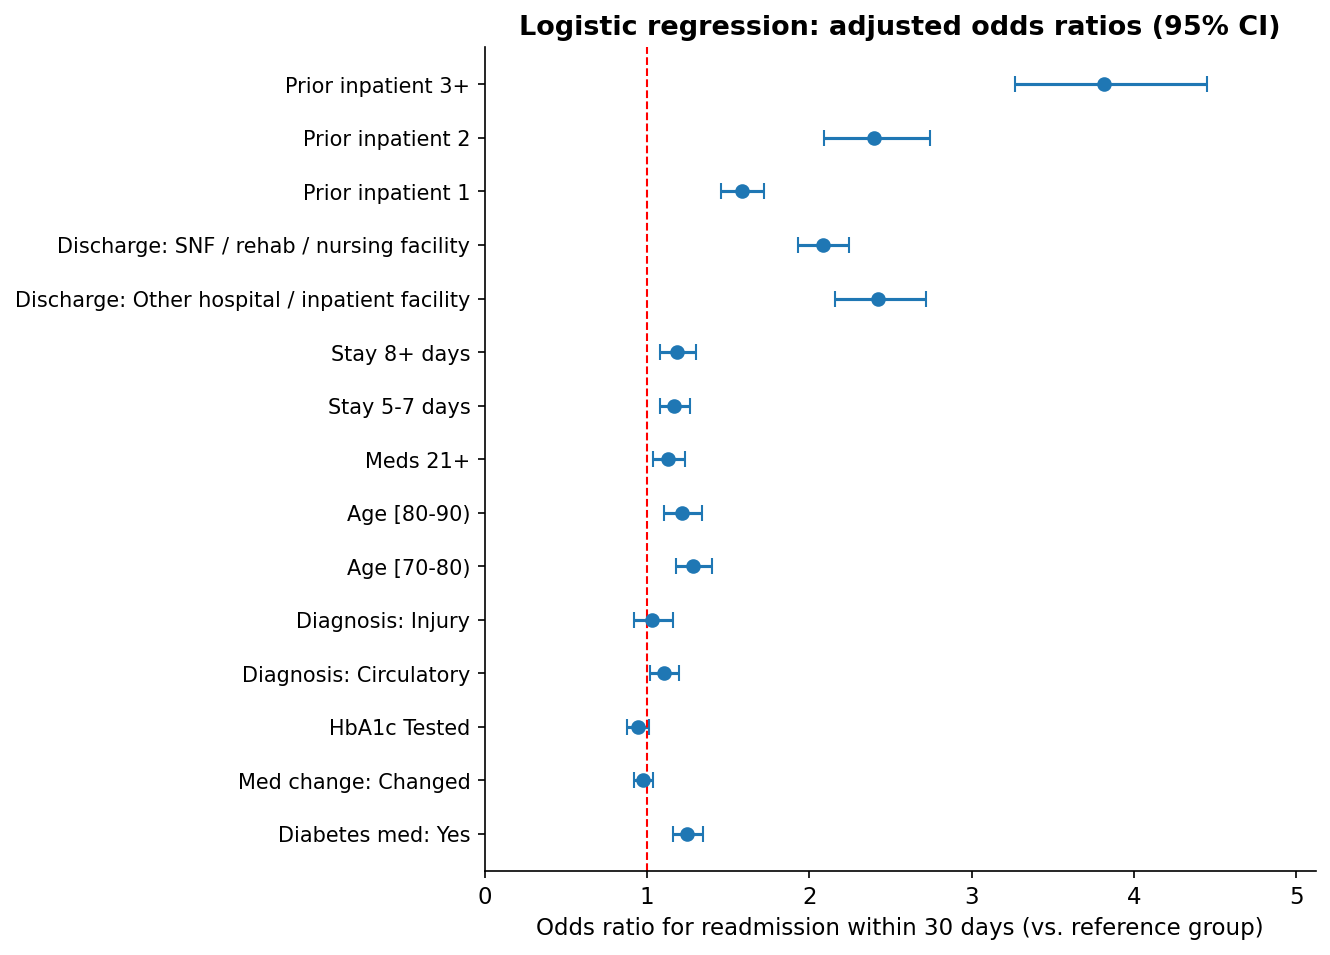

In [ ]:
import statsmodels.api as sm

model_df = df.copy()
model_df['race'] = model_df['race'].fillna('Missing')
dummies = pd.get_dummies(
    model_df[['age_group', 'race', 'gender', 'admission_type', 'discharge_group',
              'diag_1_category', 'prior_inpatient_group', 'los_group',
              'meds_group', 'a1c_tested', 'med_change', 'diab_med']],
    drop_first=False, dtype=float)
refs = ['age_group_[50-60)', 'race_Caucasian', 'gender_Male',
        'admission_type_Elective', 'discharge_group_Home',
        'diag_1_category_Other', 'prior_inpatient_group_0',
        'los_group_1-2 days', 'meds_group_1-10',
        'a1c_tested_Not tested', 'med_change_No change', 'diab_med_No']
X = sm.add_constant(dummies.drop(columns=[c for c in refs if c in dummies.columns]))
logit = sm.Logit(model_df['readmitted_30d'].astype(float), X).fit(disp=0, maxiter=200)
print(f"McFadden pseudo-R2: {logit.prsquared:.4f}, n = {int(logit.nobs):,}, "
      f"converged: {logit.mle_retvals.get('converged')}")
conf = logit.conf_int()
or_table = pd.DataFrame({
    'odds_ratio': np.exp(logit.params),
    'ci_low': np.exp(conf[0]), 'ci_high': np.exp(conf[1]),
    'p': logit.pvalues}).drop(index='const').sort_values('odds_ratio', ascending=False)
print(or_table.round(3).to_string())


## 9. Cost illustration and recommendations

**Cost basis (external):** AHRQ HCUP Statistical Brief #278 (Weiss & Jiang, 2021) reports an average 30-day readmission cost of **$15,200** (2018 USD). This is a national all-cause average, not a diabetes-specific cost, so the dollar figures below are illustrative.

- The cohort had 6,284 readmissions within 30 days, about **$95.5M** at that average cost.
- The 896 patients with 3+ prior inpatient visits produced 237 readmissions, about **$3.6M**. A program that cut readmissions in that one small group by 20% would avoid ~47 readmissions, roughly **$714,000**.

**Recommendations (all framed as associations in this dataset):**

1. **Prioritize the 896 patients with 3+ prior inpatient visits (26.5% readmission rate).** Same-week follow-up calls and a post-discharge check-in for this group first — it is 1.3% of patients but 3.8% of readmissions.
2. **Pay special attention at discharge to a facility.** SNF / rehab discharges readmit at 14.8% and other-hospital transfers at 16.3%, vs 6.9% for home. Coordinate the handoff and confirm the receiving facility has the medication list.
3. **Flag long stays and heavy medication loads at discharge.** Stays of 8+ days readmit at 11.8% vs 7.2% for 1–2 day stays; 21+ medications at 10.5% vs 7.3% for 1–10. A medication review before discharge is the cheapest intervention in this list.
4. **Do not use HbA1c testing as a lever on this evidence.** Tested patients readmitted slightly less often (8.4% vs 9.1%), but the association is small and not significant after adjustment (OR 0.94, p = 0.11). Treat it as a data-quality note, not an intervention.
5. **Do not target by gender or race.** Gender shows no association (p = 0.58) and race differences are small and not significant after adjustment. Age matters (70–90 readmit at 10–11%), but it is not actionable the way prior use is.

**Limitations:** data is from 1999–2008 and covers diabetic patients only, so rates and patterns may not match a current general population. The dataset has no post-discharge care, socioeconomic, or clinical-severity variables, and the model explains little of the variation (pseudo-R² = 0.035). Discharge destination and medication change are markers of how sick a patient already is, not proof that the destination or the change caused the readmission.